# Mini-project 27: Full matched GDSC2 evaluation

Executed evidence viewer for the saved five-fold results. **This notebook does not refit the models**; use `model_code/full_gdsc_benchmark.py` to train/reproduce folds.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
ROOT=Path.cwd()
if not (ROOT/'research/full_gdsc/summary.csv').exists(): ROOT=ROOT.parent
D=ROOT/'research/full_gdsc'
summary=pd.read_csv(D/'summary.csv')
print('Full data audit:',pd.read_json(D/'audit.json',typ='series')[['matched_cells','matched_drug_groups','matched_pairs']].to_dict())
print(summary[['mode','model','folds','rmse_mean','rmse_sd','r_mean']].round(4).to_string(index=False))

Full data audit: {'matched_cells': 649, 'matched_drug_groups': 286, 'matched_pairs': 160512}
mode                 model  folds  rmse_mean  rmse_sd  r_mean
cell             cell_only      5     2.6894   0.0163  0.2041
cell cell_plus_annotations      5     1.3553   0.0395  0.8696
cell             drug_mean      5     1.4623   0.0600  0.8467
cell           global_mean      5     2.7445   0.0254     NaN
drug             cell_only      5     2.6506   0.2791  0.2588
drug cell_plus_annotations      5     2.3873   0.1751  0.4762
drug           global_mean      5     2.7422   0.2779     NaN


In [2]:
p=pd.read_csv(D/'fold_predictions.csv')
m=pd.read_csv(D/'fold_metrics.csv')
assert len(p)==321024 and len(m)==35
for key,g in p.groupby(['mode','fold']):
    y=g.LN_IC50.to_numpy(float)
    for model in ['global_mean','cell_only','cell_plus_annotations']+(['drug_mean'] if key[0]=='cell' else []):
        r=m[(m['mode']==key[0])&(m['fold']==key[1])&(m.model==model)].iloc[0]
        calc=float(np.sqrt(np.mean((y-g['pred_'+model].to_numpy(float))**2)))
        assert np.isclose(calc,r.rmse,atol=1e-7)
print('Verification: all 35 recorded fold metrics recomputed from actual test observations.')

Verification: all 35 recorded fold metrics recomputed from actual test observations.


In [3]:
sk=pd.read_csv(D/'per_drug_skill_cell_holdout.csv')
print('Median within-drug Pearson:',round(float(sk.r.median()),4))
print('Drugs beating training per-drug mean:',int((sk.delta_rmse>0).sum()),'/',len(sk))
print(sk[sk.drug.isin(['selumetinib','trametinib','pd0325901'])].round(3).to_string(index=False))

Median within-drug Pearson: 0.4492
Drugs beating training per-drug mean: 229 / 286
       drug  baseline  model      r  response_sd  delta_rmse
  pd0325901     2.095  2.217 -0.005        2.092      -0.122
selumetinib     1.735  1.840  0.052        1.732      -0.105
 trametinib     2.226  2.371 -0.047        2.224      -0.144


Figure: 01_full_kfold_rmse.png


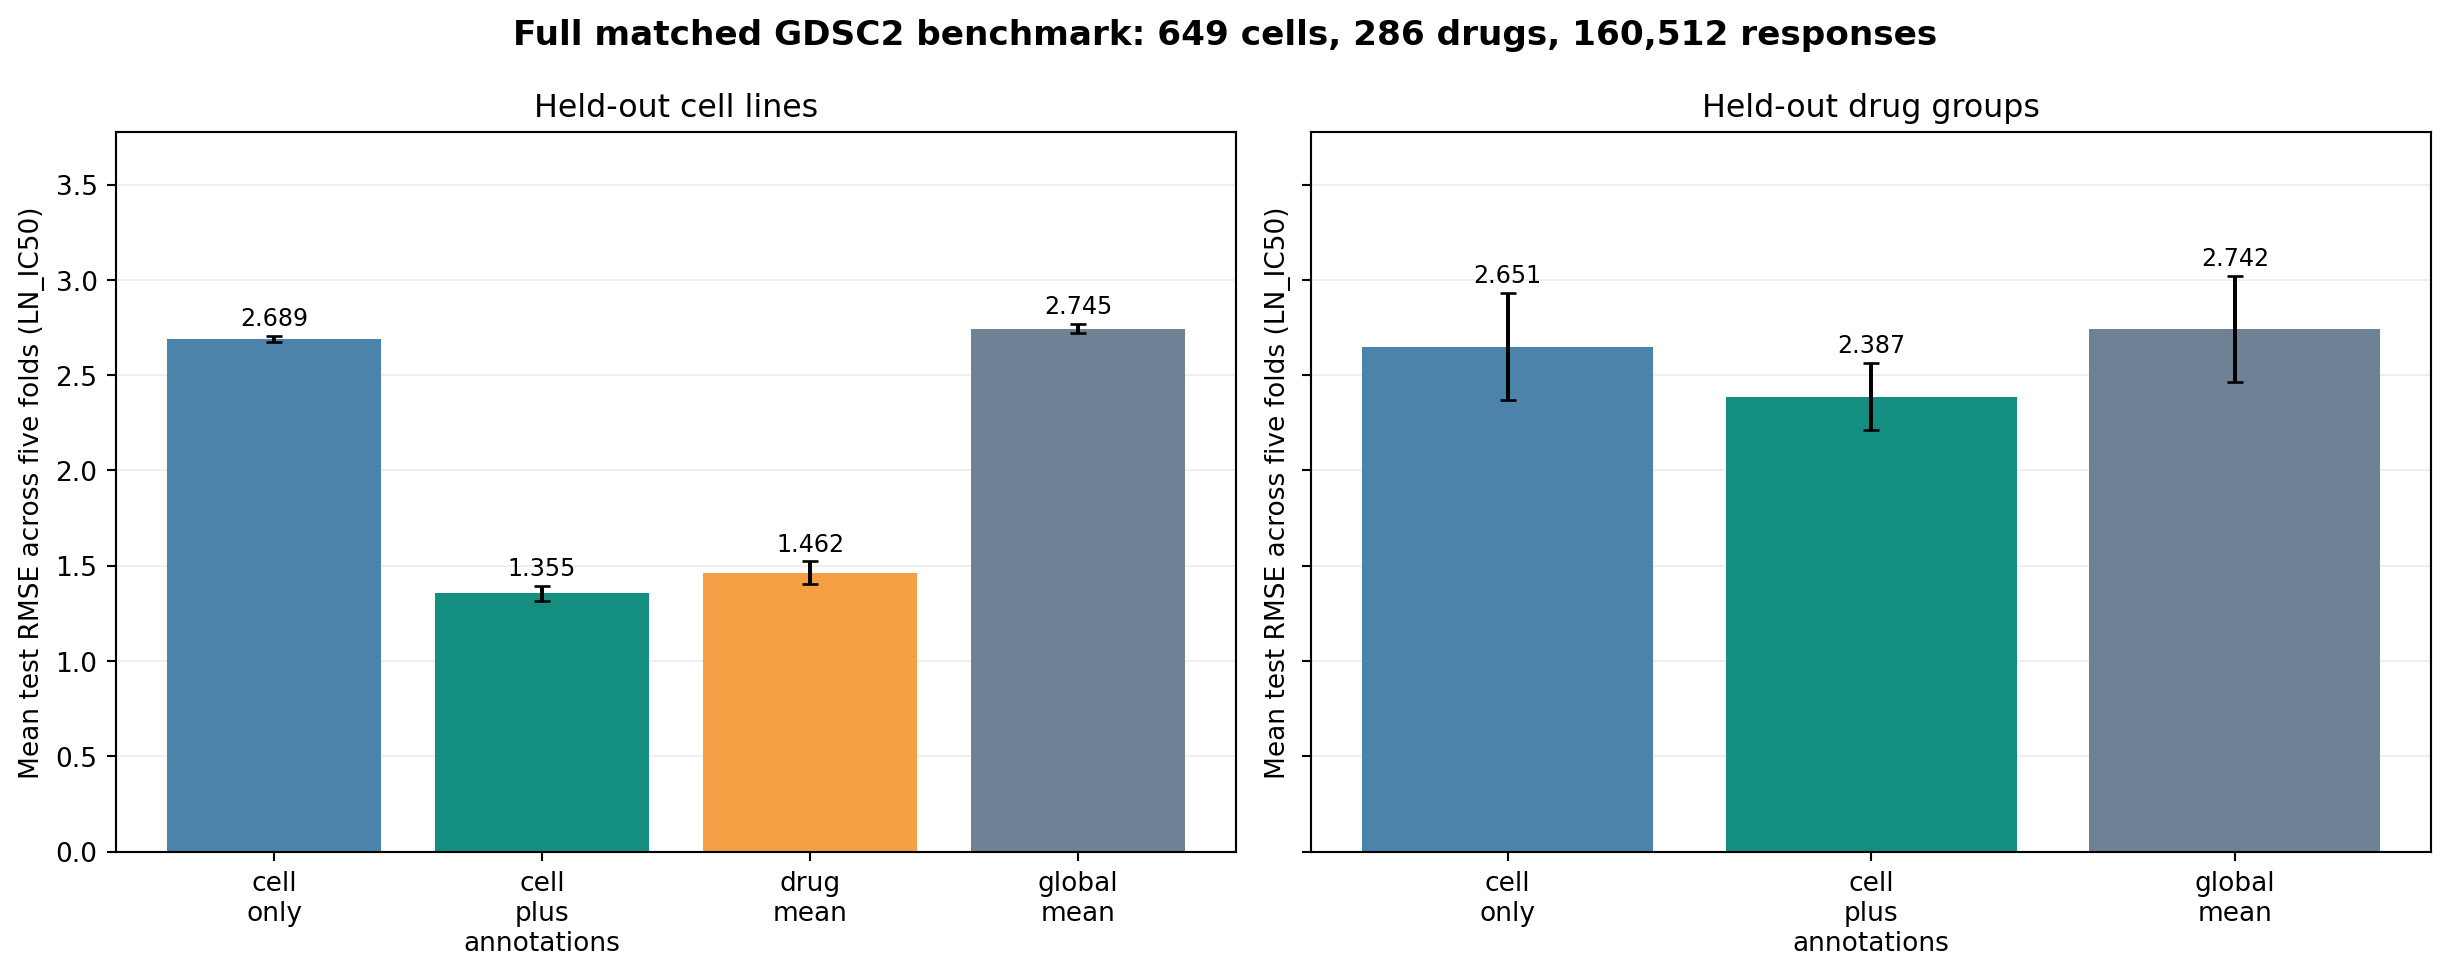

Figure: 02_within_drug_pearson.png


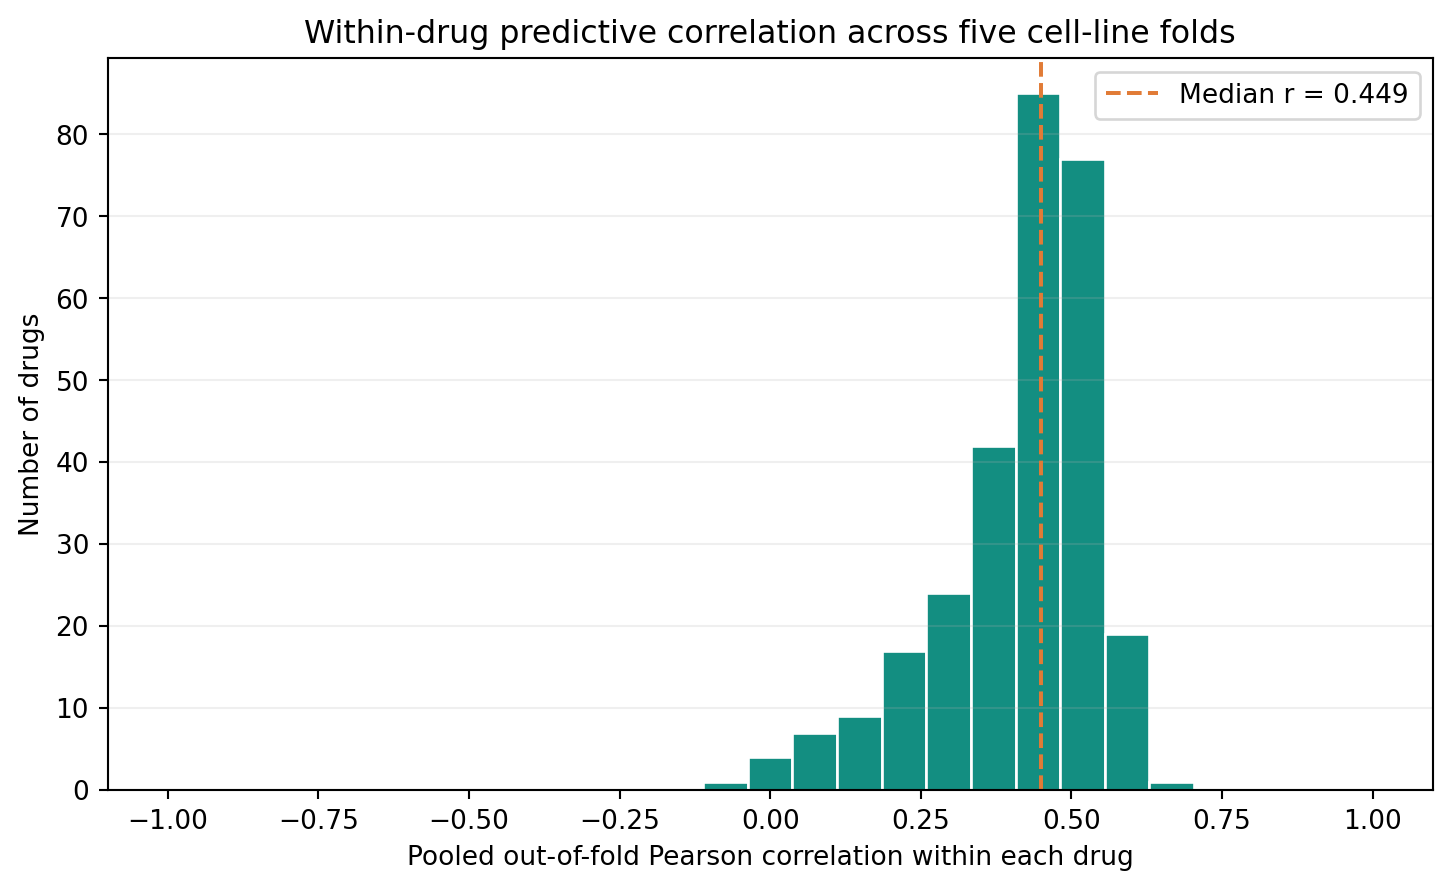

Figure: 05_biological_drug_models.png


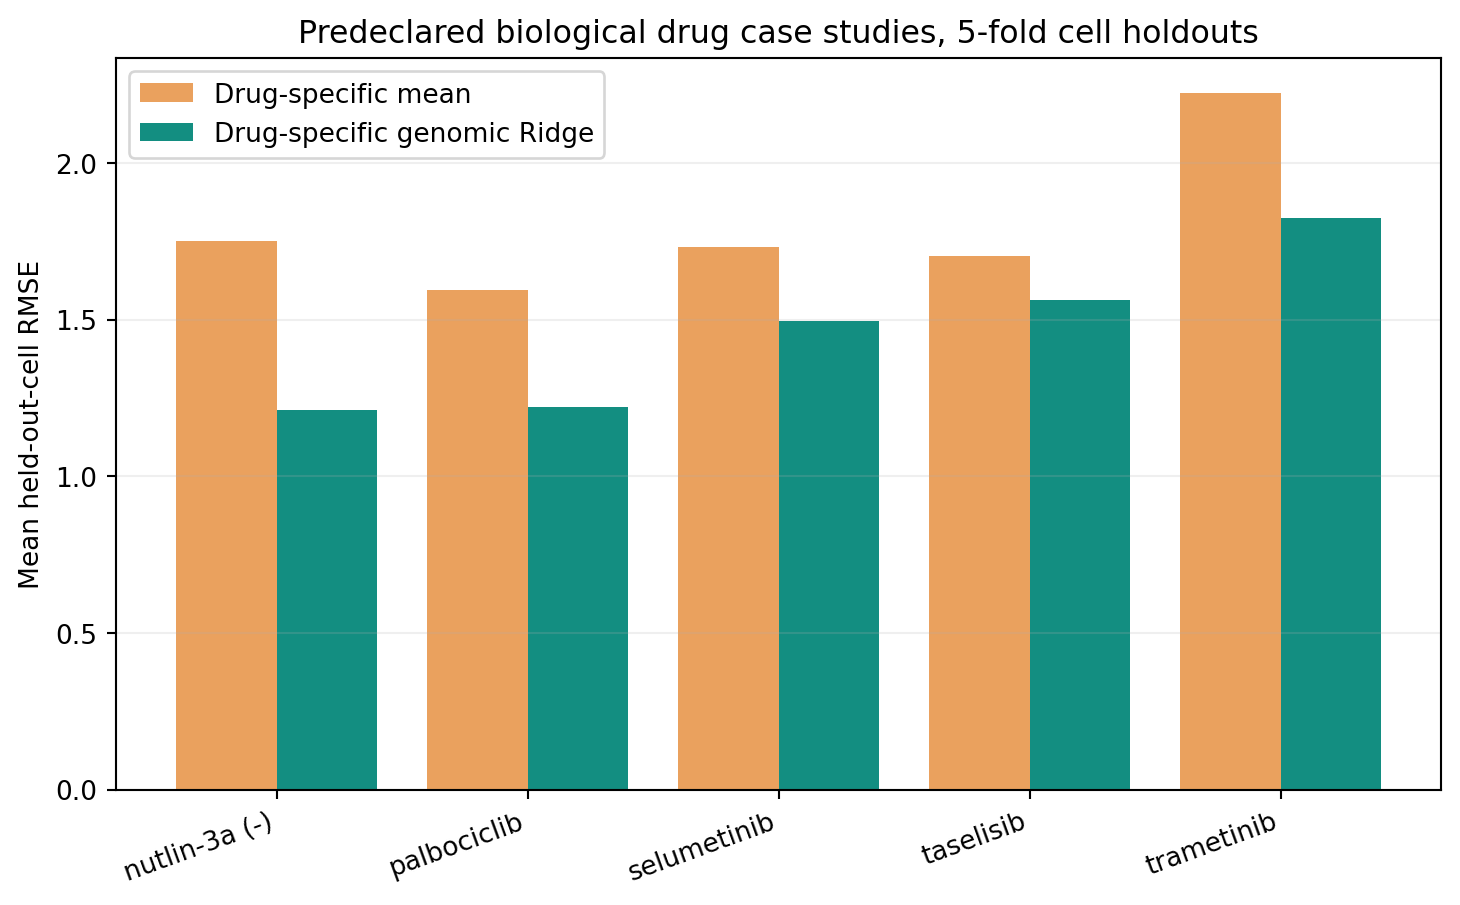

In [4]:
from IPython.display import display,Image
for name in ['01_full_kfold_rmse.png','02_within_drug_pearson.png','05_biological_drug_models.png']:
    print('Figure:',name)
    display(Image(filename=str(D/'figures'/name),width=650))

## Scope boundary
The full matched set has 649 cell lines and 286 drug-name groups, not all raw GDSC2 measurements. Drug structures are not verified for the entire 286-group universe. No true cross-screen PRISM validation, patient-level prediction, or causal biomarker result is claimed.